In [ ]:
# Step 1: Load the three JSON datasets

import json
import pandas as pd

# Load flights data
with open("/content/flights.json", "r") as file:
    flights_data = json.load(file)

# Load hotels data
with open("/content/hotels.json", "r") as file:
    hotels_data = json.load(file)

# Load places data
with open("/content/places.json", "r") as file:
    places_data = json.load(file)

# Convert JSON data into DataFrames
flights_df = pd.DataFrame(flights_data)
hotels_df = pd.DataFrame(hotels_data)
places_df = pd.DataFrame(places_data)

# Display dataset sizes
print("Flights dataset:", flights_df.shape)
print("Hotels dataset:", hotels_df.shape)
print("Places dataset:", places_df.shape)

Flights dataset: (30, 7)
Hotels dataset: (40, 6)
Places dataset: (40, 5)


In [ ]:
# Step 2: Check the structure of all three datasets

print("========== FLIGHTS DATASET ==========")
print(flights_df.info())
print("\nColumns:", flights_df.columns.tolist())

print("\n========== HOTELS DATASET ==========")
print(hotels_df.info())
print("\nColumns:", hotels_df.columns.tolist())

print("\n========== PLACES DATASET ==========")
print(places_df.info())
print("\nColumns:", places_df.columns.tolist())

========== FLIGHTS DATASET ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   flight_id       30 non-null     object
 1   airline         30 non-null     object
 2   from            30 non-null     object
 3   to              30 non-null     object
 4   departure_time  30 non-null     object
 5   arrival_time    30 non-null     object
 6   price           30 non-null     int64 
dtypes: int64(1), object(6)
memory usage: 1.8+ KB
None

Columns: ['flight_id', 'airline', 'from', 'to', 'departure_time', 'arrival_time', 'price']

========== HOTELS DATASET ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   hotel_id         40 non-null     object
 1   name             40 non-null     obje

## Chart 1: Number of Flights by Airline

### Objective
This visualization shows the number of flights available for each airline in the dataset.

### Why is this important?
Understanding the distribution of flights across airlines helps identify which airlines have greater representation in the available flight data. This can be useful for the travel planning assistant when comparing available flight options.

### Visualization
A bar chart is used because the objective is to compare the number of flights across different airline categories.

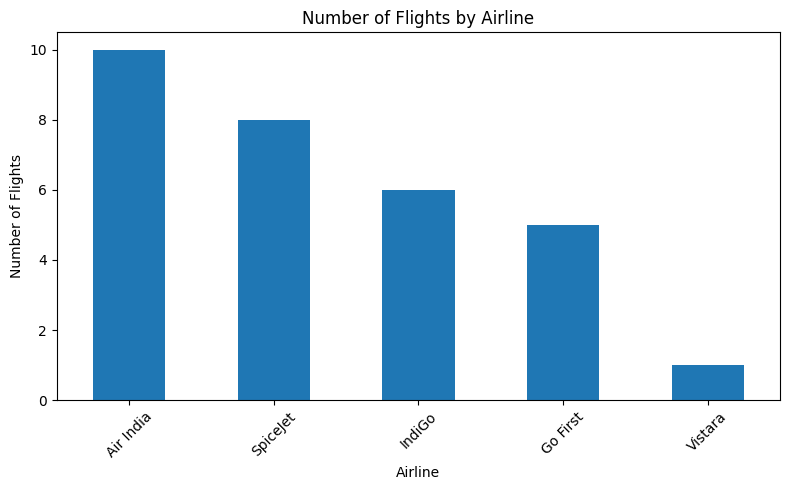

In [ ]:
# Chart 1: Number of flights by airline

import matplotlib.pyplot as plt

# Count flights for each airline
airline_counts = flights_df["airline"].value_counts()

# Create the bar chart
plt.figure(figsize=(8, 5))
airline_counts.plot(kind="bar")

plt.title("Number of Flights by Airline")
plt.xlabel("Airline")
plt.ylabel("Number of Flights")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### Interpretation

The chart shows that **Air India has the highest number of flights** in the dataset, followed by **SpiceJet** and **IndiGo**.

- Air India has 10 flights.
- SpiceJet has 8 flights.
- IndiGo has 6 flights.
- Go First has 5 flights.
- Vistara has 1 flight.

This indicates that Air India has the largest representation among the airlines in the available dataset, while Vistara has the smallest representation.

This information can help the travel planning assistant understand the availability of flight options across different airlines.

## Chart 2: Number of Flights by Origin City

### Objective
This visualization shows the number of flights departing from each origin city in the dataset.

### Why is this important?
The origin city is an important factor in travel planning because the availability of flights can vary between departure locations. Understanding the distribution of flights across origin cities helps identify cities with more available flight options.

### Visualization
A bar chart is used to compare the number of flights departing from different origin cities.

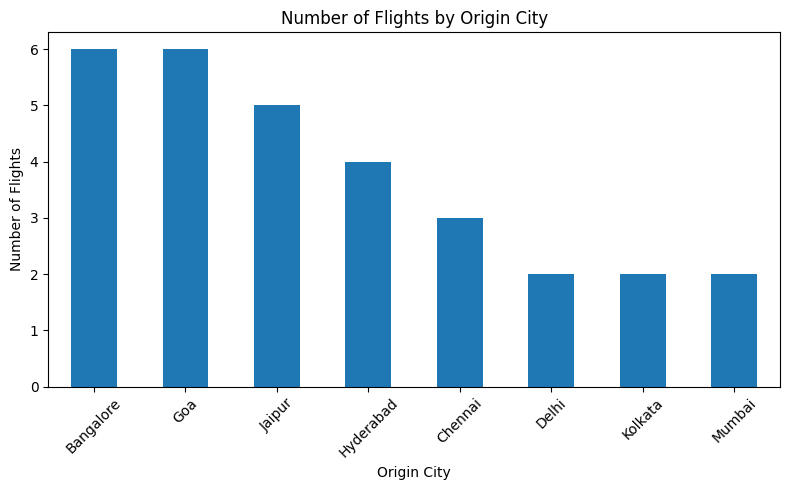

In [ ]:
# Chart 2: Number of flights by origin city

# Count flights from each origin city
origin_counts = flights_df["from"].value_counts()

# Create the bar chart
plt.figure(figsize=(8, 5))
origin_counts.plot(kind="bar")

plt.title("Number of Flights by Origin City")
plt.xlabel("Origin City")
plt.ylabel("Number of Flights")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### Interpretation

The chart shows the distribution of flights across different origin cities.

- **Bangalore and Goa** have the highest number of departing flights, with 6 flights each.
- **Jaipur** has 5 departing flights.
- **Hyderabad** has 4 departing flights.
- **Chennai** has 3 departing flights.
- **Delhi, Kolkata, and Mumbai** have 2 departing flights each.

This shows that Bangalore and Goa have the highest representation as origin cities in the dataset, while Delhi, Kolkata, and Mumbai have comparatively fewer available flights.

For the travel planning assistant, the availability of flights from different origin cities can help determine the possible travel options for a user based on their starting location.

## Chart 3: Number of Flights by Destination City

### Objective
This visualization shows the number of flights arriving at each destination city in the dataset.

### Why is this important?
Destination availability is an important factor in travel planning. A city with more incoming flight options may provide greater flexibility when the travel assistant searches for suitable flights.

### Visualization
A bar chart is used to compare the number of flights arriving at different destination cities.

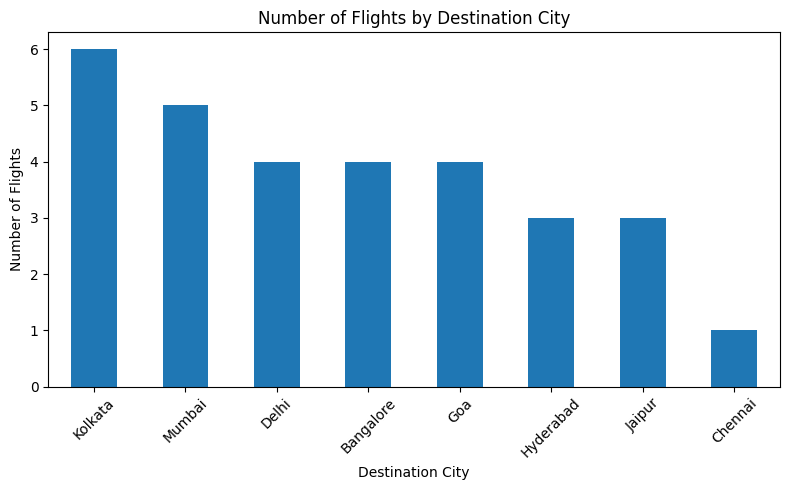

In [ ]:
# Chart 3: Number of flights by destination city

# Count flights arriving at each destination city
destination_counts = flights_df["to"].value_counts()

# Create the bar chart
plt.figure(figsize=(8, 5))
destination_counts.plot(kind="bar")

plt.title("Number of Flights by Destination City")
plt.xlabel("Destination City")
plt.ylabel("Number of Flights")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### Interpretation

The chart shows the distribution of flights across different destination cities.

- **Kolkata** has the highest number of incoming flights, with 6 flights.
- **Mumbai** has 5 incoming flights.
- **Delhi, Bangalore, and Goa** each have 4 incoming flights.
- **Hyderabad and Jaipur** each have 3 incoming flights.
- **Chennai** has the lowest number of incoming flights, with only 1 flight.

This indicates that Kolkata has the highest representation as a destination in the dataset, while Chennai has the lowest.

For the travel planning assistant, this information helps identify destinations with greater or fewer flight availability and can be considered when searching for suitable travel options.

## Chart 4: Average Flight Price by Airline

### Objective
This visualization compares the average ticket price across different airlines in the dataset.

### Why is this important?
Price is one of the most important factors in travel planning. Comparing average prices across airlines helps identify airlines that generally offer lower or higher-priced flight options.

### Visualization
A bar chart is used to compare the average flight price for each airline.

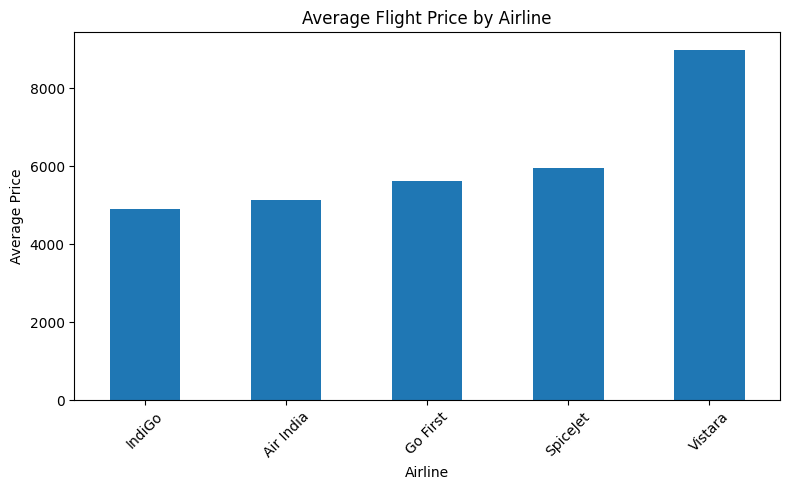

In [ ]:
# Chart 4: Average flight price by airline

# Calculate the average flight price for each airline
average_price_airline = flights_df.groupby("airline")["price"].mean().sort_values()

# Create the bar chart
plt.figure(figsize=(8, 5))
average_price_airline.plot(kind="bar")

plt.title("Average Flight Price by Airline")
plt.xlabel("Airline")
plt.ylabel("Average Price")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### Interpretation

The chart compares the average flight price across the five airlines in the dataset.

- **IndiGo** has the lowest average flight price, at approximately ₹4,900.
- **Air India** has an average price of approximately ₹5,100.
- **Go First** has an average price of approximately ₹5,600.
- **SpiceJet** has an average price of approximately ₹5,900.
- **Vistara** has the highest average flight price, at approximately ₹9,000.

The results show that Vistara is considerably more expensive on average than the other airlines in this dataset, while IndiGo has the lowest average ticket price.

This analysis is particularly relevant to the travel planning assistant because flight price is an important factor when recommending options based on a user's budget.

## Chart 5: Distribution of Flight Prices

### Objective
This visualization shows how flight prices are distributed across all flights in the dataset.

### Why is this important?
Understanding the distribution of flight prices helps identify the typical price range of flights and determine whether the dataset contains unusually low or high-priced flight options.

### Visualization
A histogram is used to visualize the frequency of flights across different price ranges.

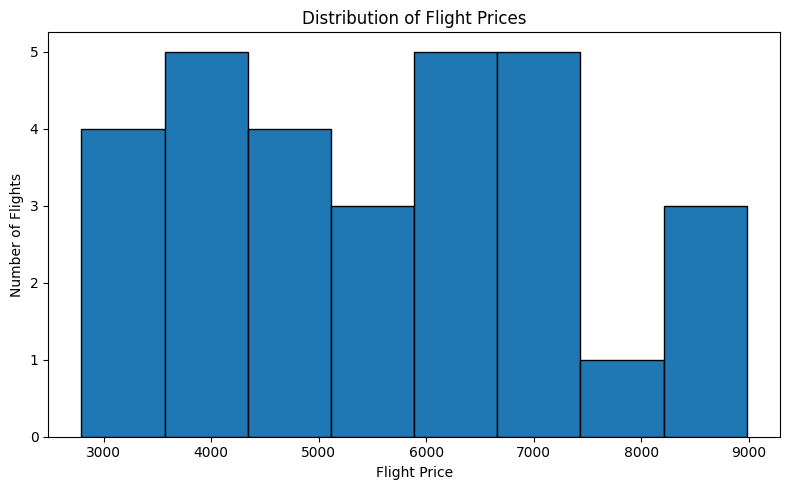

In [ ]:
# Chart 5: Distribution of flight prices

plt.figure(figsize=(8, 5))

plt.hist(flights_df["price"], bins=8, edgecolor="black")

plt.title("Distribution of Flight Prices")
plt.xlabel("Flight Price")
plt.ylabel("Number of Flights")
plt.tight_layout()

plt.show()

### Interpretation

The histogram shows the distribution of flight prices across all flights in the dataset.

- Flight prices range approximately from **₹2,700 to ₹9,000**.
- A large proportion of flights are concentrated between approximately **₹3,500 and ₹7,500**.
- There are relatively fewer flights in the higher price range around **₹7,500–₹8,300**.
- A smaller group of flights is present again in the higher range of approximately **₹8,300–₹9,000**.

Overall, the dataset contains flights across a broad range of prices, which indicates that the travel planning assistant will need to consider different budget levels when recommending flights.

This distribution can also help in setting realistic price expectations for users during travel planning.

## Chart 6: Average Flight Price by Origin City

### Objective
This visualization compares the average flight price for flights departing from different origin cities.

### Why is this important?
Flight prices can vary depending on the departure city. Understanding these differences can help the travel planning assistant identify relatively expensive or affordable departure options when constructing an itinerary.

### Visualization
A bar chart is used to compare the average flight price across different origin cities.

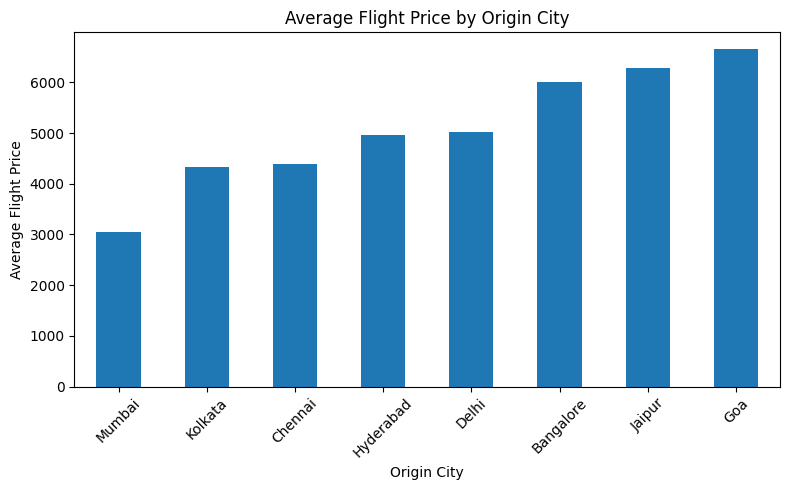

In [ ]:
# Chart 6: Average flight price by origin city

# Calculate the average flight price for each origin city
average_price_origin = flights_df.groupby("from")["price"].mean().sort_values()

# Create the bar chart
plt.figure(figsize=(8, 5))
average_price_origin.plot(kind="bar")

plt.title("Average Flight Price by Origin City")
plt.xlabel("Origin City")
plt.ylabel("Average Flight Price")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### Interpretation

The chart compares the average flight price across different origin cities.

- **Mumbai** has the lowest average flight price, at approximately ₹3,000.
- **Kolkata** and **Chennai** have average prices of approximately ₹4,300 and ₹4,400 respectively.
- **Hyderabad** has an average price of approximately ₹4,900.
- **Delhi** has an average price of approximately ₹5,000.
- **Bangalore** has an average price of approximately ₹6,000.
- **Jaipur** has an average price of approximately ₹6,300.
- **Goa** has the highest average flight price, at approximately ₹6,600.

The results show considerable variation in average flight prices across origin cities. Mumbai offers the lowest average-priced flights in this dataset, while Goa has the highest average-priced flights.

This analysis is useful for the travel planning assistant because the user's departure city can have a significant impact on the estimated travel budget.

## Chart 7: Average Hotel Price by Star Rating

### Objective
This visualization compares the average price per night of hotels across different star ratings.

### Why is this important?
Hotel category and price are important factors in travel planning. Analyzing the relationship between star rating and average price helps understand how accommodation costs vary with hotel quality.

This information can help the travel planning assistant recommend hotels that match a user's preferred quality level and budget.

### Visualization
A bar chart is used to compare the average nightly hotel price across different star ratings.

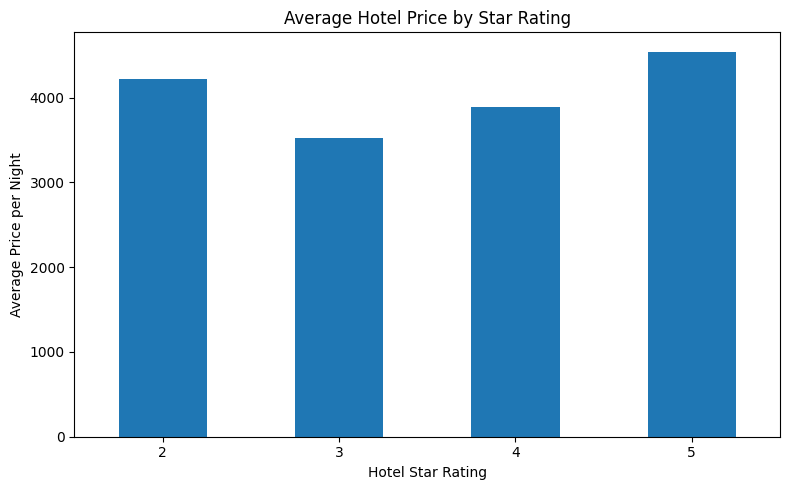

In [ ]:
# Chart 7: Average hotel price by star rating

# Calculate the average hotel price for each star rating
average_price_stars = hotels_df.groupby("stars")["price_per_night"].mean()

# Create the bar chart
plt.figure(figsize=(8, 5))
average_price_stars.plot(kind="bar")

plt.title("Average Hotel Price by Star Rating")
plt.xlabel("Hotel Star Rating")
plt.ylabel("Average Price per Night")
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

### Interpretation

The chart compares the average nightly price of hotels across different star ratings.

- **2-star hotels** have an average price of approximately ₹4,200 per night.
- **3-star hotels** have the lowest average price, at approximately ₹3,500 per night.
- **4-star hotels** have an average price of approximately ₹3,900 per night.
- **5-star hotels** have the highest average price, at approximately ₹4,500 per night.

The results show that hotel prices do not increase consistently with star rating in this dataset. Although 5-star hotels have the highest average price, 3-star hotels are cheaper than 2-star and 4-star hotels.

This suggests that factors other than star rating may also influence hotel prices. Therefore, the travel planning assistant should consider both **hotel category and price** when recommending accommodation options.

## Chart 8: Distribution of Hotel Prices

### Objective
This visualization shows how hotel prices per night are distributed across all hotels in the dataset.

### Why is this important?
Understanding the distribution of hotel prices helps identify the common price range of accommodations and whether the dataset contains relatively low- or high-priced hotels.

This information is useful for the travel planning assistant when estimating accommodation costs and matching hotels to different user budgets.

### Visualization
A histogram is used to show the frequency of hotels across different nightly price ranges.

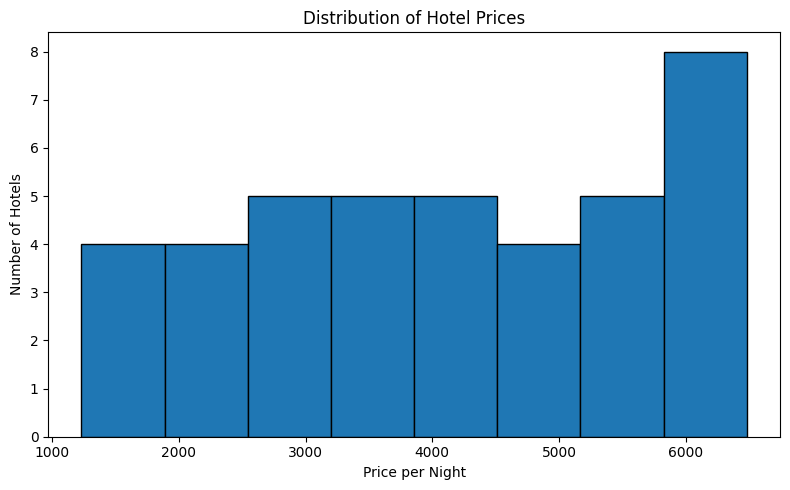

In [ ]:
# Chart 8: Distribution of hotel prices

plt.figure(figsize=(8, 5))

plt.hist(
    hotels_df["price_per_night"],
    bins=8,
    edgecolor="black"
)

plt.title("Distribution of Hotel Prices")
plt.xlabel("Price per Night")
plt.ylabel("Number of Hotels")
plt.tight_layout()

plt.show()

### Interpretation

The histogram shows the distribution of nightly hotel prices across the dataset.

- Hotel prices range approximately from **₹1,200 to ₹6,500 per night**.
- Hotels in the lower price ranges, around **₹1,200–₹2,500**, account for a smaller portion of the dataset.
- A considerable number of hotels fall within the middle price range of approximately **₹2,500–₹5,500 per night**.
- The highest concentration is observed in the upper price range of approximately **₹5,500–₹6,500**, which contains the largest number of hotels.

Overall, the dataset contains hotels across a wide range of price levels, providing accommodation options for users with different budgets.

This distribution is useful for the travel planning assistant because it can help estimate accommodation costs and identify hotels that fit within a user's specified budget.

## Chart 9: Hotel Price vs. Star Rating

### Objective
This visualization examines the relationship between hotel star rating and the price per night for individual hotels.

### Why is this important?
Star rating can influence the price of accommodation, but it may not be the only factor affecting hotel prices. Analyzing individual hotels helps us understand whether higher-rated hotels generally have higher prices and whether there are exceptions.

This is useful for the travel planning assistant because hotel recommendations should consider both the user's preferred hotel category and their budget.

### Visualization
A scatter plot is used because it shows the relationship between two numerical variables: hotel star rating and price per night.

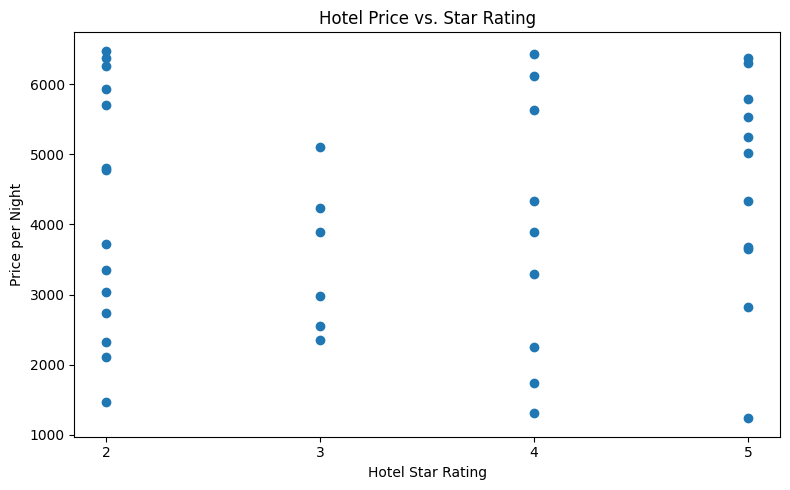

In [ ]:
# Chart 9: Hotel price vs. star rating

plt.figure(figsize=(8, 5))

plt.scatter(
    hotels_df["stars"],
    hotels_df["price_per_night"]
)

plt.title("Hotel Price vs. Star Rating")
plt.xlabel("Hotel Star Rating")
plt.ylabel("Price per Night")
plt.xticks(sorted(hotels_df["stars"].unique()))
plt.tight_layout()

plt.show()

### Interpretation

The scatter plot shows the relationship between hotel star rating and price per night.

The prices show considerable variation within each star category. For example, 2-star hotels include prices ranging from approximately ₹1,500 to above ₹6,000, while 5-star hotels also show a wide range of prices.

The plot does not show a clear linear relationship where the price consistently increases with every additional star rating. Some lower-rated hotels have prices comparable to or higher than hotels with higher star ratings.

This indicates that star rating alone is not sufficient to determine hotel price. Other factors, such as location and available amenities, may also influence accommodation costs.

For the travel planning assistant, this suggests that hotel recommendations should consider multiple factors rather than relying only on star rating.

## Chart 10: Average Hotel Price by City

### Objective
This visualization compares the average nightly hotel price across different cities.

### Why is this important?
Accommodation costs can vary considerably between destinations. Understanding these differences is important for estimating the total travel budget and selecting destinations that match a user's financial preferences.

### Visualization
A bar chart is used to compare the average hotel price per night across different cities.

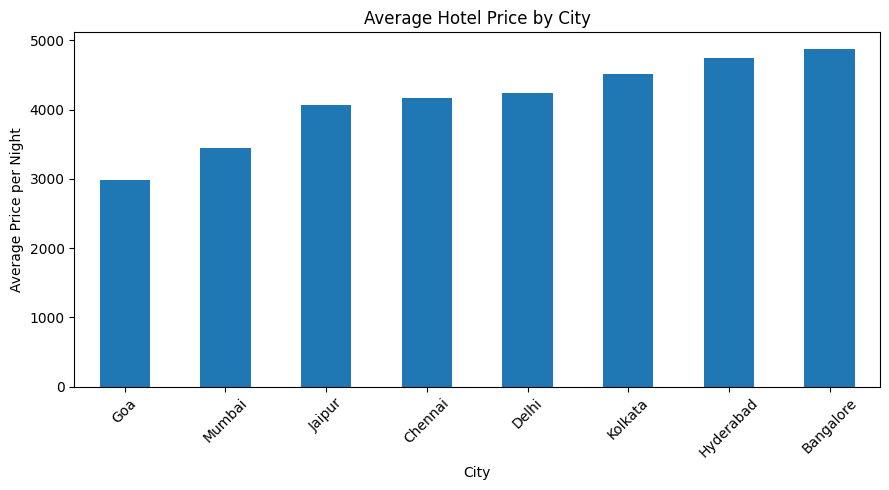

In [ ]:
# Chart 10: Average hotel price by city

# Calculate the average hotel price for each city
average_hotel_price_city = (
    hotels_df.groupby("city")["price_per_night"]
    .mean()
    .sort_values()
)

# Create the bar chart
plt.figure(figsize=(9, 5))
average_hotel_price_city.plot(kind="bar")

plt.title("Average Hotel Price by City")
plt.xlabel("City")
plt.ylabel("Average Price per Night")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### Interpretation

The chart compares the average nightly hotel price across different cities.

- **Goa** has the lowest average hotel price, at approximately ₹3,000 per night.
- **Mumbai** has an average price of approximately ₹3,500 per night.
- **Jaipur** has an average price of approximately ₹4,100 per night.
- **Chennai** has an average price of approximately ₹4,200 per night.
- **Delhi** has an average price of approximately ₹4,300 per night.
- **Kolkata** has an average price of approximately ₹4,500 per night.
- **Hyderabad** has an average price of approximately ₹4,700 per night.
- **Bangalore** has the highest average hotel price, at approximately ₹4,900 per night.

The results show that accommodation costs vary considerably across destinations. Goa has the lowest average hotel price in this dataset, while Bangalore has the highest.

This is relevant to the travel planning assistant because the choice of destination can have a significant impact on the overall accommodation budget.

In [ ]:
# Check the different amenities available in the hotel dataset

print("Unique amenities entries:")
print(hotels_df["amenities"].value_counts())

Unique amenities entries:
amenities
[wifi, pool, gym]                        2
[gym, breakfast, wifi, parking]          1
[wifi, pool]                             1
[wifi, parking, spa, breakfast]          1
[gym, breakfast]                         1
[gym, parking, pool]                     1
[pool, parking]                          1
[pool, breakfast, spa, gym, wifi]        1
[gym, breakfast, pool, wifi]             1
[breakfast, gym, spa, wifi]              1
[breakfast, spa, gym, wifi]              1
[spa, gym, pool, breakfast]              1
[parking, breakfast, spa, pool]          1
[wifi, parking, breakfast, pool]         1
[spa, pool, wifi, gym]                   1
[wifi, parking, gym]                     1
[breakfast, wifi]                        1
[breakfast, gym]                         1
[parking, spa, wifi, pool, gym]          1
[wifi, gym, parking, pool, spa]          1
[spa, parking, breakfast]                1
[breakfast, spa, wifi, parking]          1
[wifi, spa, pool, 

## Chart 11: Most Common Hotel Amenities

### Objective
This visualization shows how frequently individual amenities are available across the hotels in the dataset.

### Why is this important?
Amenities are an important factor when users select accommodation. Understanding which amenities are most commonly available helps the travel planning assistant identify the facilities that users are most likely to find when searching for hotels.

### Data Preparation
The `amenities` column contains multiple amenities stored together for each hotel. Therefore, the individual amenities are extracted and counted separately before creating the visualization.

### Visualization
A bar chart is used to compare the frequency of different hotel amenities.

In [ ]:
# Check how the amenities are actually stored

print(hotels_df["amenities"].iloc[0])
print(type(hotels_df["amenities"].iloc[0]))

['wifi', 'pool']
<class 'list'>


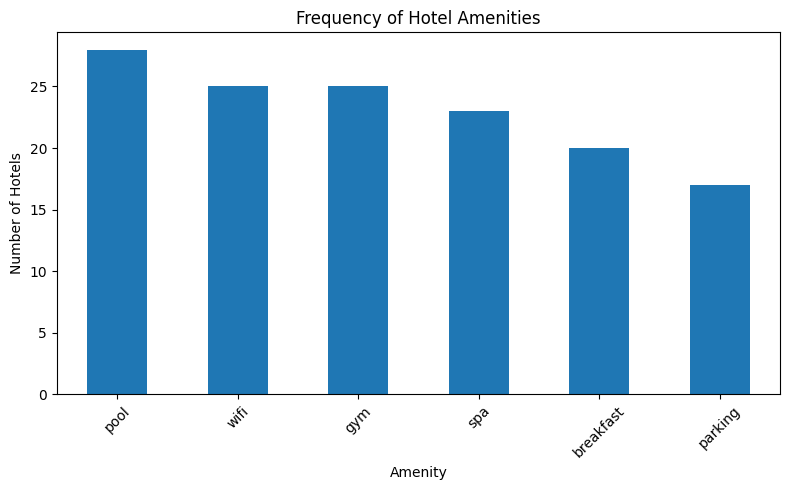

In [ ]:
# Chart 11: Frequency of individual hotel amenities

# Expand the list of amenities so that each amenity gets its own row
amenities_exploded = hotels_df["amenities"].explode()

# Count how many hotels provide each individual amenity
amenity_counts = amenities_exploded.value_counts().sort_values(ascending=False)

# Create the bar chart
plt.figure(figsize=(8, 5))
amenity_counts.plot(kind="bar")

plt.title("Frequency of Hotel Amenities")
plt.xlabel("Amenity")
plt.ylabel("Number of Hotels")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### Interpretation

The chart shows the frequency of individual amenities across the hotels in the dataset.

- **Pool** is the most common amenity, available at 28 hotels.
- **WiFi** and **gym** are each available at 25 hotels.
- **Spa** is available at 23 hotels.
- **Breakfast** is available at 20 hotels.
- **Parking** is the least common amenity, available at 17 hotels.

The results show that recreational and connectivity-related facilities such as pools, WiFi, and gyms are widely available across the hotels. Parking and breakfast are comparatively less common.

This information can help the travel planning assistant consider user preferences for specific hotel amenities when recommending accommodation options.

## Chart 12: Number of Places by Type

### Objective
This visualization shows the number of places available for each type of attraction in the dataset.

### Why is this important?
Travelers may have different preferences, such as historical sites, beaches, museums, or religious places. Understanding the distribution of attraction types helps determine the variety of experiences available to users.

This information can support the travel planning assistant when selecting places based on a user's interests and preferences.

### Visualization
A bar chart is used to compare the number of places across different attraction types.

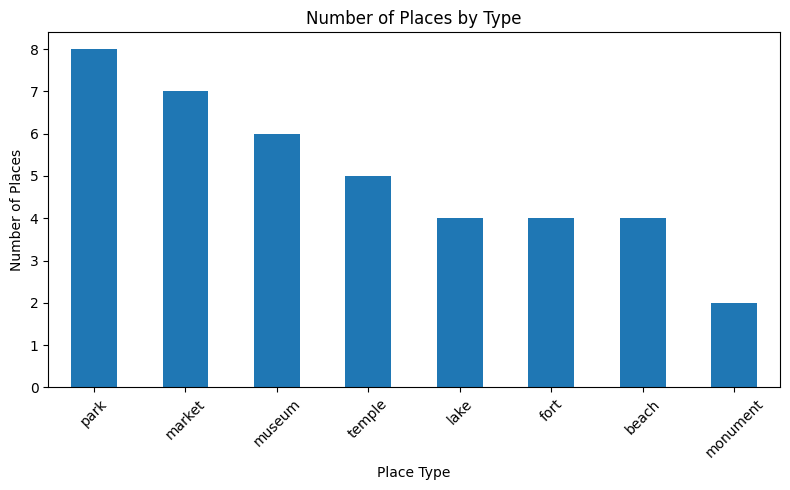

In [ ]:
# Chart 12: Number of places by type

# Count the number of places for each type
place_type_counts = places_df["type"].value_counts()

# Create the bar chart
plt.figure(figsize=(8, 5))
place_type_counts.plot(kind="bar")

plt.title("Number of Places by Type")
plt.xlabel("Place Type")
plt.ylabel("Number of Places")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### Interpretation

The chart shows the distribution of different types of places available in the dataset.

- **Parks** are the most common type, with 8 places.
- **Markets** are the second most common, with 7 places.
- **Museums** account for 6 places.
- **Temples** account for 5 places.
- **Lakes, forts, and beaches** each have 4 places.
- **Monuments** are the least represented category, with 2 places.

The dataset therefore contains a variety of attraction types, with parks and markets having the highest representation.

This variety is useful for the travel planning assistant because it provides different types of attractions that can be considered according to a user's interests and preferences.

## Chart 13: Average Place Rating by Type

### Objective
This visualization compares the average user rating of different types of places in the dataset.

### Why is this important?
The number of available attractions alone does not indicate their quality or popularity. Comparing average ratings helps identify which types of places receive higher ratings from users.

This information can help the travel planning assistant prioritize highly rated attractions when generating personalized itineraries.

### Visualization
A bar chart is used to compare the average rating across different place types.

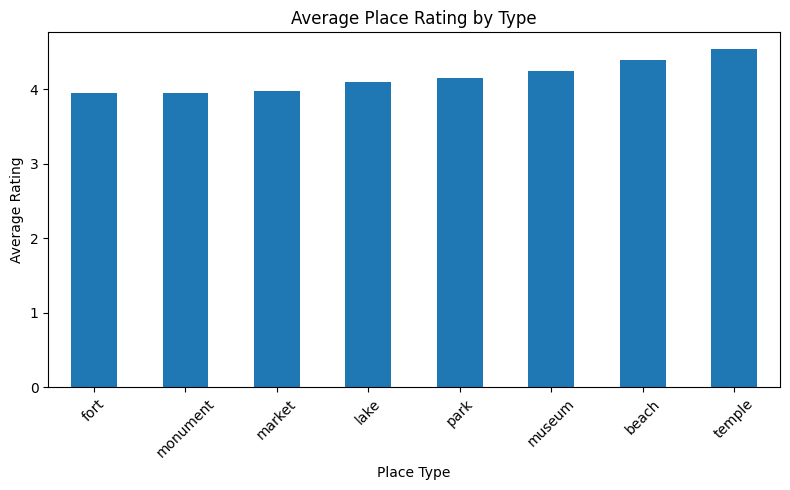

In [ ]:
# Chart 13: Average place rating by type

# Calculate the average rating for each place type
average_rating_type = (
    places_df.groupby("type")["rating"]
    .mean()
    .sort_values()
)

# Create the bar chart
plt.figure(figsize=(8, 5))
average_rating_type.plot(kind="bar")

plt.title("Average Place Rating by Type")
plt.xlabel("Place Type")
plt.ylabel("Average Rating")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### Interpretation

The chart compares the average ratings of different types of places in the dataset.

- **Temples** have the highest average rating, at approximately 4.5.
- **Beaches** have the second-highest average rating, at approximately 4.4.
- **Museums** have an average rating of approximately 4.2.
- **Parks** have an average rating of approximately 4.1.
- **Lakes** have an average rating of approximately 4.1.
- **Markets** have an average rating of approximately 4.0.
- **Forts** and **monuments** have the lowest average ratings, at approximately 3.9.

Overall, most place types have relatively high average ratings, with temples and beaches receiving the highest ratings in this dataset.

This information can help the travel planning assistant prioritize highly rated attraction types when generating personalized itineraries based on user preferences.

## Chart 14: Average Place Rating by City

### Objective
This visualization compares the average rating of tourist places across different cities.

### Why is this important?
Different destinations may offer attractions with different average ratings. Understanding these differences can help the travel planning assistant identify cities that have highly rated places.

This can support destination selection and help generate itineraries that prioritize cities with better-rated attractions.

### Visualization
A bar chart is used to compare the average place rating across different cities.

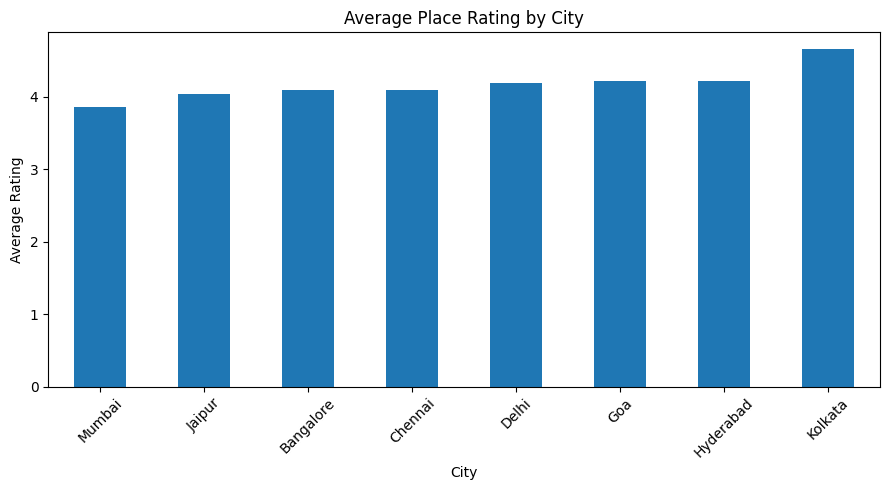

In [ ]:
# Chart 14: Average place rating by city

# Calculate the average rating for each city
average_rating_city = (
    places_df.groupby("city")["rating"]
    .mean()
    .sort_values()
)

# Create the bar chart
plt.figure(figsize=(9, 5))
average_rating_city.plot(kind="bar")

plt.title("Average Place Rating by City")
plt.xlabel("City")
plt.ylabel("Average Rating")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### Interpretation

The chart compares the average rating of tourist places across different cities.

- **Kolkata** has the highest average place rating, at approximately 4.6.
- **Delhi, Goa, and Hyderabad** have average ratings of approximately 4.2.
- **Bangalore and Chennai** have average ratings of approximately 4.1.
- **Jaipur** has an average rating of approximately 4.0.
- **Mumbai** has the lowest average place rating, at approximately 3.9.

The results show that Kolkata has the highest average rating for places in this dataset, while Mumbai has the lowest.

However, the differences between most cities are relatively small, indicating that the dataset contains generally well-rated attractions across all destinations.

This analysis can help the travel planning assistant compare destinations based on the average rating of their available attractions when generating personalized travel recommendations.

## Chart 15: Average Hotel Price by Number of Amenities

### Objective
This visualization compares the average nightly hotel price based on the number of amenities offered by each hotel.

### Why is this important?
Hotels offering a larger number of amenities may provide more facilities and services to travelers. Understanding how hotel prices vary with the number of amenities can help the travel planning assistant balance accommodation features with the user's budget.

### Data Preparation
The `amenities` column contains a list of amenities for each hotel. The number of amenities available at each hotel is calculated before comparing it with the hotel's nightly price.

### Visualization
A bar chart is used to compare the average hotel price for different numbers of amenities.

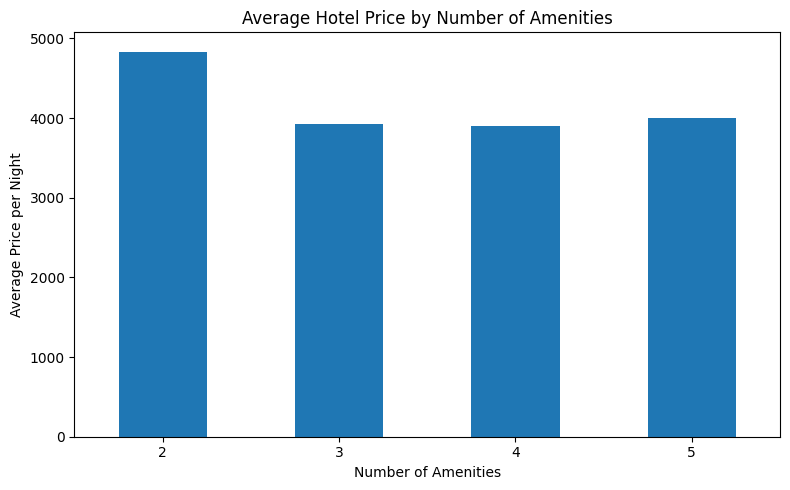

In [ ]:
# Chart 15: Average hotel price by number of amenities

# Calculate the number of amenities for each hotel
amenity_count = hotels_df["amenities"].apply(len)

# Calculate the average hotel price for each number of amenities
average_price_amenities = (
    hotels_df.assign(amenity_count=amenity_count)
    .groupby("amenity_count")["price_per_night"]
    .mean()
    .sort_index()
)

# Create the bar chart
plt.figure(figsize=(8, 5))
average_price_amenities.plot(kind="bar")

plt.title("Average Hotel Price by Number of Amenities")
plt.xlabel("Number of Amenities")
plt.ylabel("Average Price per Night")
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

### Interpretation

The chart compares the average nightly hotel price based on the number of amenities offered.

- Hotels with **2 amenities** have the highest average price, at approximately ₹4,800 per night.
- Hotels with **3 amenities** have an average price of approximately ₹3,900 per night.
- Hotels with **4 amenities** have an average price of approximately ₹3,900 per night.
- Hotels with **5 amenities** have an average price of approximately ₹4,000 per night.

The results do not show a consistent relationship between the number of amenities and hotel price. Hotels with fewer amenities can have higher prices than hotels offering more amenities.

This indicates that the number of amenities alone is not sufficient to explain hotel pricing. Other factors such as location, star rating, and the specific amenities offered may also influence the price.

## Chart 16: Distribution of Place Ratings

### Objective
This visualization shows how the ratings of tourist places are distributed across the dataset.

### Why is this important?
Understanding the overall rating distribution helps determine the general quality of attractions available in the dataset. It also helps identify whether most places receive high ratings or whether ratings are spread across a wider range.

This information can help the travel planning assistant prioritize highly rated attractions when generating itineraries.

### Visualization
A histogram is used to show the frequency of places across different rating ranges.

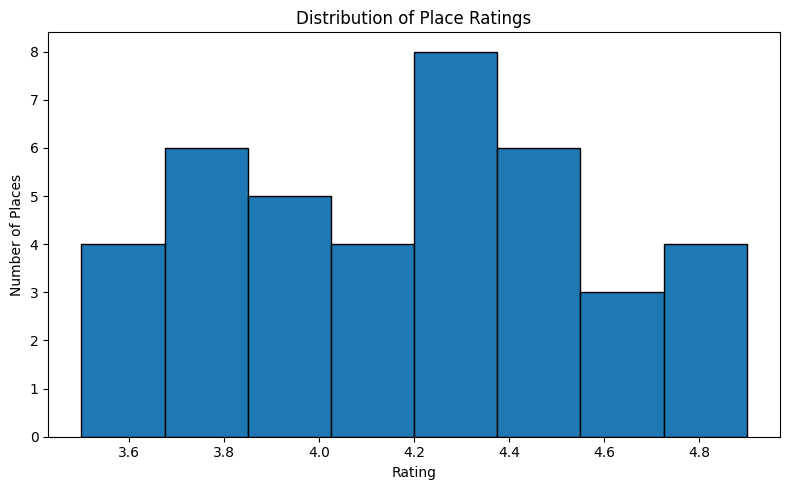

In [ ]:
# Chart 16: Distribution of place ratings

plt.figure(figsize=(8, 5))

plt.hist(
    places_df["rating"],
    bins=8,
    edgecolor="black"
)

plt.title("Distribution of Place Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Places")
plt.tight_layout()

plt.show()

### Interpretation

The histogram shows the distribution of ratings across all tourist places in the dataset.

- The ratings range approximately from **3.5 to 4.9**.
- The highest concentration of places is around the **4.2–4.4** rating range, with 8 places.
- Approximately 6 places fall in the **3.7–3.9** range.
- Approximately 6 places fall in the **4.4–4.6** range.
- Fewer places have ratings around **4.6–4.7**.
- There are also 4 places in the highest range of approximately **4.7–4.9**.

Overall, most attractions in the dataset have relatively high ratings, with the majority of places receiving ratings above 4.0.

This indicates that the travel planning assistant has a dataset containing generally well-rated attractions, which can support recommendations focused on highly rated places.

## Chart 17: Distribution of Hotels by Star Rating

### Objective
This visualization shows the proportion of hotels belonging to each star rating category.

### Why is this important?
Understanding the composition of the hotel dataset helps determine how accommodation options are distributed across different quality categories.

This information is useful for the travel planning assistant because users may have different preferences for budget, mid-range, or premium accommodation.

### Visualization
A pie chart is used to show the proportion of hotels belonging to each star-rating category.

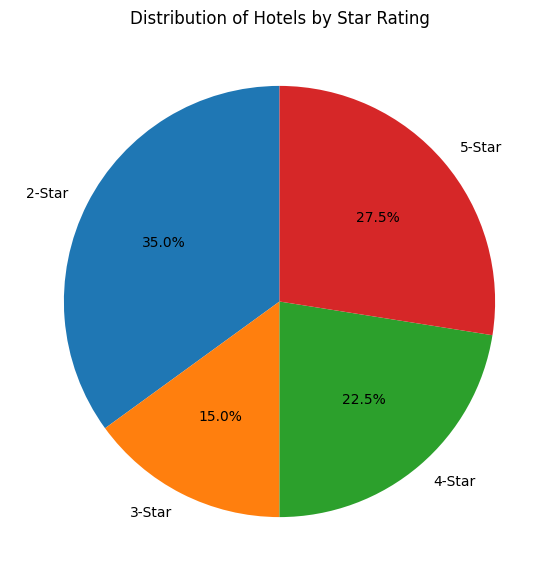

In [ ]:
# Chart 17: Distribution of hotels by star rating

# Count hotels in each star-rating category
star_counts = hotels_df["stars"].value_counts().sort_index()

# Create the pie chart
plt.figure(figsize=(7, 7))

plt.pie(
    star_counts,
    labels=[f"{stars}-Star" for stars in star_counts.index],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribution of Hotels by Star Rating")

plt.show()

### Interpretation

The pie chart shows the composition of hotels across different star-rating categories.

- **2-star hotels** form the largest category, representing **35%** of all hotels.
- **5-star hotels** represent **27.5%** of the dataset.
- **4-star hotels** account for **22.5%** of the hotels.
- **3-star hotels** represent the smallest category, accounting for **15%**.

Overall, the dataset contains a larger proportion of 2-star and 5-star hotels, while 3-star hotels are comparatively less represented.

This distribution provides a mix of budget and premium accommodation options, which can be useful for the travel planning assistant when recommending hotels according to different user preferences and budgets.

# Overall Exploratory Data Analysis Findings

The exploratory analysis was performed on the three provided datasets: flights, hotels, and places.

## Flights Dataset

The flights dataset contains 30 flight records covering multiple airlines, origin cities, and destination cities.

The analysis shows that:

- Air India has the highest number of flights in the dataset, while Vistara has the fewest.
- The number of flights varies across origin and destination cities, indicating different levels of flight availability.
- Vistara has the highest average flight price among the airlines, while IndiGo has the lowest average price.
- Flight prices are distributed across a broad range, approximately from ₹2,500 to ₹9,000.
- Average flight prices also vary considerably by origin city, with Goa having one of the highest average prices and Mumbai having the lowest.

These findings show that both airline selection and departure city can influence flight costs and availability.

## Hotels Dataset

The hotels dataset contains 40 hotel records across multiple cities, with information about star rating, nightly price, and amenities.

The analysis shows that:

- Hotel prices vary considerably across different cities.
- Bangalore has the highest average hotel price, while Goa has the lowest average hotel price in the dataset.
- Hotel prices vary substantially within individual star-rating categories, indicating that star rating alone does not determine price.
- Pool, WiFi, and gym are among the most frequently available amenities, while parking is comparatively less common.
- The number of amenities does not show a simple direct relationship with hotel price.
- The dataset contains a mixture of 2-star, 3-star, 4-star, and 5-star hotels, providing accommodation options across different categories.

These findings suggest that hotel recommendations should consider multiple factors, including city, price, star rating, and amenities.

## Places Dataset

The places dataset contains 40 tourist attractions across multiple cities, including information about attraction type and rating.

The analysis shows that:

- Parks and markets are the most frequently represented attraction types.
- Temples and beaches have among the highest average ratings by attraction type.
- Place ratings generally fall in the higher range, indicating that most attractions in the dataset are well rated.
- Average place ratings vary across cities, with Kolkata having the highest average rating and Mumbai having the lowest in this dataset.

These findings indicate that the places dataset provides a variety of attractions that can be selected according to user interests and ratings.

## Overall EDA Conclusion

The exploratory analysis shows that travel planning requires considering multiple factors rather than relying on a single variable.

Flight price and availability vary by airline and city. Hotel cost varies by destination, star rating, and available amenities. Tourist attractions differ in type, location, and rating.

Therefore, the travel planning assistant should combine information from flights, hotels, places, weather, user preferences, and budget rather than making recommendations based on a single criterion.

These findings provide the foundation for developing the agentic travel planning workflow using LangChain.

# Phase 2: Agentic AI Travel Planning System

After completing the exploratory data analysis, the next stage is to build the agentic travel planning system.

The system will use the provided flight, hotel, and places datasets along with real-time weather information to create personalized travel plans.

## Planned Workflow

1. Prepare the datasets for tool usage
2. Build the Flight Search Tool
3. Build the Hotel Recommendation Tool
4. Build the Places Discovery Tool
5. Build the Weather Lookup Tool
6. Build the Budget Estimation Tool
7. Integrate the tools with a LangChain agent
8. Generate a structured travel itinerary
9. Test the agent with different travel requests
10. Build the Streamlit interface

The final system will combine these components to provide flight recommendations, hotel suggestions, attractions, weather information, and estimated travel costs.

In [ ]:
# Check the Python environment and installed LangChain packages

import sys

print("Python version:")
print(sys.version)

print("\nChecking LangChain packages...")

try:
    import langchain
    print("LangChain version:", langchain.__version__)
except ImportError:
    print("LangChain is not installed.")

try:
    import langchain_openai
    print("langchain-openai is installed.")
except ImportError:
    print("langchain-openai is not installed.")

try:
    import langchain_core
    print("langchain-core is installed.")
except ImportError:
    print("langchain-core is not installed.")

Python version:
3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]

Checking LangChain packages...
LangChain version: 1.4.8
langchain-openai is not installed.
langchain-core is installed.


In [ ]:
# Install the OpenAI integration for LangChain

!pip install -q -U langchain-openai

In [ ]:
# Verify that the LangChain OpenAI integration is installed

import langchain_openai

print("langchain-openai is installed successfully.")
print("Version:", langchain_openai.__version__)

langchain-openai is installed successfully.
Version: 1.8.5


In [36]:
# Check that the Google API key is available in Colab Secrets
from google.colab import userdata

google_api_key = userdata.get("Google-API-Key")

if google_api_key:
    print("Google API key loaded successfully.")
    print("Key is securely stored and hidden.")
else:
    print("Google API key was not found.")

Google API key loaded successfully.
Key is securely stored and hidden.


In [37]:
# Step 6: Install LangChain's Google Gemini integration

!pip install -q -U langchain-google-genai

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.2 which is incompatible.
google-adk 2.7.1 requires google-genai<3,>=2.12.1, but you have google-genai 3.6.1 which is incompatible.


In [38]:
# Step 7: Verify the Google Gemini LangChain integration

from langchain_google_genai import ChatGoogleGenerativeAI

print("langchain-google-genai is installed successfully.")

langchain-google-genai is installed successfully.


In [41]:
# Step 9: Check Gemini API connection without using LangChain

from google.colab import userdata
from google import genai

# Load the API key securely
google_api_key = userdata.get("Google-API-Key")

# Create the Gemini client
client = genai.Client(api_key=google_api_key)

print("Gemini client created successfully.")

Gemini client created successfully.


In [43]:
# Step 11: Check which Gemini models are available for this API key

models = client.models.list()

for model in models:
    if "generateContent" in model.supported_actions:
        print(model.name)

models/gemini-2.5-flash
models/gemini-2.5-pro
models/gemma-4-26b-a4b-it
models/gemma-4-31b-it
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3.1-flash-lite
models/gemini-3-pro-image
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-nano-banana-2.1
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash
models/gemini-4-argon
models/gemini-4-carbon
models/gemini-4-hydrogen
models/gemini-4-neon
models/antigravity-preview-05-2026
models/antigravity-preview-09-2026
models/antigravity-preview-latest
models/deep-research-max-preview-04-2026
models/deep-research-preview-04-2026
models/deep-research-pro-preview-12-2025


In [46]:
# Step 14: Test Gemini 3.5 Flash Lite

response = client.models.generate_content(
    model="gemini-3.5-flash-lite",
    contents="Say exactly: Travel assistant connection successful."
)

print(response.text)

Travel assistant connection successful.


In [47]:
# Step 15: Create the Gemini LLM for our travel assistant

from google.colab import userdata
from langchain_google_genai import ChatGoogleGenerativeAI

# Load the Google API key securely
google_api_key = userdata.get("Google-API-Key")

# Create the Gemini language model
llm = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    google_api_key=google_api_key,
    temperature=0
)

print("Gemini LLM is ready for LangChain.")

Gemini LLM is ready for LangChain.


In [48]:
# Step 16: Create the Flight Search Tool

def search_flights(origin, destination):
    """
    Search for flights between an origin and destination city.

    Parameters:
        origin (str): Departure city.
        destination (str): Arrival city.

    Returns:
        pandas.DataFrame: Matching flights.
    """

    # Filter flights based on origin and destination
    results = flights_df[
        (flights_df["from"].str.lower() == origin.lower()) &
        (flights_df["to"].str.lower() == destination.lower())
    ]

    # Sort flights from cheapest to most expensive
    results = results.sort_values("price")

    return results

In [49]:
# Step 17: Test the Flight Search Tool

# Display available origin-destination routes
print(
    flights_df[["from", "to"]]
    .drop_duplicates()
    .sort_values(["from", "to"])
    .to_string(index=False)
)

     from        to
Bangalore     Delhi
Bangalore       Goa
Bangalore   Kolkata
Bangalore    Mumbai
  Chennai Bangalore
  Chennai Hyderabad
  Chennai    Mumbai
    Delhi   Kolkata
      Goa Bangalore
      Goa Hyderabad
      Goa    Jaipur
      Goa   Kolkata
      Goa    Mumbai
Hyderabad     Delhi
Hyderabad       Goa
Hyderabad   Kolkata
Hyderabad    Mumbai
   Jaipur Bangalore
   Jaipur   Chennai
   Jaipur     Delhi
   Jaipur   Kolkata
   Jaipur    Mumbai
  Kolkata    Jaipur
   Mumbai       Goa
   Mumbai Hyderabad


In [50]:
# Step 18: Test the Flight Search Tool

# Search for flights from Delhi to Kolkata
flight_results = search_flights("Delhi", "Kolkata")

# Display the matching flights
print(flight_results.to_string(index=False))

flight_id   airline  from      to      departure_time        arrival_time  price
   FL0002 Air India Delhi Kolkata 2025-11-26T05:34:00 2025-11-26T09:34:00   3779
   FL0028 Air India Delhi Kolkata 2025-07-14T21:50:00 2025-07-14T23:50:00   6265


In [51]:
# Step 19: Create the Hotel Recommendation Tool

def search_hotels(city, min_stars=0):
    """
    Search for hotels in a city.

    Parameters:
        city (str): Destination city.
        min_stars (int): Minimum hotel star rating.

    Returns:
        pandas.DataFrame: Matching hotels sorted by price.
    """

    # Filter hotels by city
    results = hotels_df[
        hotels_df["city"].str.lower() == city.lower()
    ]

    # Filter by minimum star rating
    results = results[
        results["stars"] >= min_stars
    ]

    # Sort hotels from cheapest to most expensive
    results = results.sort_values("price_per_night")

    return results

In [52]:
# Step 20: Test the Hotel Recommendation Tool

# Search for hotels in Delhi with at least 4 stars
hotel_results = search_hotels("Delhi", min_stars=4)

# Display the matching hotels
print(hotel_results.to_string(index=False))

hotel_id               name  city  stars  price_per_night                       amenities  amenity_count
 HOT0002     Comfort Suites Delhi      5             3650 [gym, breakfast, wifi, parking]              4
 HOT0001 Grand Palace Hotel Delhi      4             3897                    [wifi, pool]              2
 HOT0003  Green Leaf Resort Delhi      4             6123                 [pool, parking]              2


In [53]:
# Step 21: Create the Places Discovery Tool

def search_places(city, place_type=None, min_rating=0):
    """
    Search for tourist places in a city.

    Parameters:
        city (str): Destination city.
        place_type (str): Optional type of place, such as museum, temple, park, etc.
        min_rating (float): Minimum place rating.

    Returns:
        pandas.DataFrame: Matching places sorted by rating.
    """

    # Filter places by city
    results = places_df[
        places_df["city"].str.lower() == city.lower()
    ]

    # Filter by place type if provided
    if place_type:
        results = results[
            results["type"].str.lower() == place_type.lower()
        ]

    # Filter by minimum rating
    results = results[
        results["rating"] >= min_rating
    ]

    # Sort places from highest to lowest rating
    results = results.sort_values("rating", ascending=False)

    return results

In [54]:
# Step 22: Test the Places Discovery Tool

# Search for highly rated tourist places in Delhi
place_results = search_places("Delhi", min_rating=4.0)

# Display the matching places
print(place_results.to_string(index=False))

place_id             name  city   type  rating
 PLC0001      Famous Fort Delhi   lake     4.6
 PLC0004   Popular Museum Delhi   lake     4.5
 PLC0002 Beautiful Temple Delhi temple     4.2
 PLC0003    Historic Fort Delhi museum     4.2


In [55]:
# Step 23: Create the Weather Tool

import requests


def get_weather(latitude, longitude, forecast_days=7):
    """
    Get weather forecast using the Open-Meteo API.

    Parameters:
        latitude (float): Latitude of the destination.
        longitude (float): Longitude of the destination.
        forecast_days (int): Number of forecast days.

    Returns:
        dict: Weather forecast data.
    """

    url = "https://api.open-meteo.com/v1/forecast"

    params = {
        "latitude": latitude,
        "longitude": longitude,
        "daily": [
            "temperature_2m_max",
            "temperature_2m_min",
            "weather_code"
        ],
        "forecast_days": forecast_days,
        "timezone": "auto"
    }

    try:
        response = requests.get(url, params=params, timeout=10)
        response.raise_for_status()

        return response.json()

    except requests.exceptions.RequestException as error:
        print("Weather API error:", error)
        return None

In [56]:
# Step 24: Test the Weather Tool

# Approximate coordinates for Delhi
latitude = 28.6139
longitude = 77.2090

# Get the weather forecast
weather_result = get_weather(latitude, longitude, forecast_days=3)

# Display the result
if weather_result:
    print(weather_result)
else:
    print("Unable to retrieve weather data.")

{'latitude': 28.576448, 'longitude': 77.18678, 'generationtime_ms': 0.10788440704345703, 'utc_offset_seconds': 19800, 'timezone': 'Asia/Kolkata', 'timezone_abbreviation': 'GMT+5:30', 'elevation': 214.0, 'daily_units': {'time': 'iso8601', 'temperature_2m_max': '°C', 'temperature_2m_min': '°C', 'weather_code': 'wmo code'}, 'daily': {'time': ['2026-11-20', '2026-11-21', '2026-11-22'], 'temperature_2m_max': [23.6, 23.6, 23.1], 'temperature_2m_min': [14.0, 13.9, 13.9], 'weather_code': [0, 3, 0]}}


In [57]:
# Step 25: Create the Budget Estimation Tool

def estimate_budget(flight_price, hotel_price_per_night,
                    number_of_nights, daily_activity_budget):
    """
    Estimate the total trip budget.

    Parameters:
        flight_price (float): Flight cost.
        hotel_price_per_night (float): Hotel cost per night.
        number_of_nights (int): Number of hotel nights.
        daily_activity_budget (float): Estimated daily activity cost.

    Returns:
        dict: Budget breakdown and total estimated cost.
    """

    # Calculate total hotel cost
    hotel_cost = hotel_price_per_night * number_of_nights

    # Calculate total activity cost
    activity_cost = daily_activity_budget * number_of_nights

    # Calculate total trip cost
    total_cost = flight_price + hotel_cost + activity_cost

    return {
        "flight_cost": flight_price,
        "hotel_cost": hotel_cost,
        "activity_cost": activity_cost,
        "total_cost": total_cost
    }

In [58]:
# Step 26: Test the Budget Estimation Tool

budget = estimate_budget(
    flight_price=3779,
    hotel_price_per_night=3650,
    number_of_nights=3,
    daily_activity_budget=1500
)

print("Budget Breakdown:")
print(budget)

Budget Breakdown:
{'flight_cost': 3779, 'hotel_cost': 10950, 'activity_cost': 4500, 'total_cost': 19229}


In [59]:
# Step 27: Convert the Python functions into LangChain tools

from langchain_core.tools import tool


@tool
def flight_search_tool(origin, destination):
    """Search for flights between an origin and destination city."""

    results = search_flights(origin, destination)

    return results.to_dict(orient="records")


@tool
def hotel_search_tool(city, min_stars=0):
    """Search for hotels in a city based on minimum star rating."""

    results = search_hotels(city, min_stars)

    return results.to_dict(orient="records")


@tool
def places_search_tool(city, place_type=None, min_rating=0):
    """Search for tourist places in a city."""

    results = search_places(city, place_type, min_rating)

    return results.to_dict(orient="records")


@tool
def weather_tool(latitude, longitude, forecast_days=7):
    """Get the weather forecast for a location."""

    return get_weather(latitude, longitude, forecast_days)


@tool
def budget_estimation_tool(
    flight_price,
    hotel_price_per_night,
    number_of_nights,
    daily_activity_budget
):
    """Estimate the total trip budget."""

    return estimate_budget(
        flight_price,
        hotel_price_per_night,
        number_of_nights,
        daily_activity_budget
    )


print("All 5 tools have been converted to LangChain tools.")

All 5 tools have been converted to LangChain tools.


In [60]:
# Step 28: Verify the LangChain tools

tools = [
    flight_search_tool,
    hotel_search_tool,
    places_search_tool,
    weather_tool,
    budget_estimation_tool
]

for tool in tools:
    print(tool.name)

flight_search_tool
hotel_search_tool
places_search_tool
weather_tool
budget_estimation_tool


In [61]:
# Step 29: Create the LangChain Travel Planning Agent

from langchain.agents import create_agent

# Create the agent with Gemini and the five travel tools
travel_agent = create_agent(
    model=llm,
    tools=tools,
    system_prompt="""
You are an intelligent travel planning assistant.

Your job is to help users plan trips using the available travel tools.

You can:
- Search for flights
- Recommend hotels
- Find tourist places
- Check weather forecasts
- Estimate the trip budget

Use the appropriate tools whenever the user's request requires travel data.

Consider the user's destination, preferences, budget, hotel requirements,
and number of days when making recommendations.

Provide a clear, practical, and personalized travel plan.
"""
)

print("Travel planning agent created successfully.")

Travel planning agent created successfully.


In [62]:
# Step 30: Test the LangChain agent with a simple travel request

response = travel_agent.invoke({
    "messages": [
        {
            "role": "user",
            "content": "Find the cheapest flights from Delhi to Kolkata."
        }
    ]
})

print(response["messages"][-1].content)

/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:4059: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:4059: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


[{'type': 'text', 'text': 'The cheapest flight found from Delhi to Kolkata is with **Air India** for **₹3,779** (Flight ID: FL0002, departure at 05:34 on 2025-11-26). \n\nIf you would like help finding hotels, tourist spots, or planning an itinerary for Kolkata, just let me know!', 'extras': {'signature': 'EnsKeQFpFH0TWuziY75GLvhEhiCfJT7AEbIHuZR/0vXXO/+nlrvmROFhq6x9OFaAuUs9tE4tz6s1RSWlCqFPKuXLoDdQ89cSlahwPb5x+NWO79FBmivtdcHmVzuCx54eNnVMLukE+//Nz14zUwiFiVl96zctV0RzjnEv9SI='}}]


In [63]:
# Step 31: Create coordinates for cities in the travel datasets

city_coordinates = {
    "Delhi": (28.6139, 77.2090),
    "Mumbai": (19.0760, 72.8777),
    "Bangalore": (12.9716, 77.5946),
    "Chennai": (13.0827, 80.2707),
    "Hyderabad": (17.3850, 78.4867),
    "Jaipur": (26.9124, 75.7873),
    "Kolkata": (22.5726, 88.3639),
    "Goa": (15.2993, 74.1240)
}

print("City coordinates prepared for", len(city_coordinates), "cities.")

City coordinates prepared for 8 cities.


In [65]:
# Step 32: Restore the LangChain tool decorator

from langchain_core.tools import tool as langchain_tool


@langchain_tool
def city_weather_tool(city, forecast_days=7):
    """
    Get the weather forecast for a supported city.

    Parameters:
        city (str): Name of the city.
        forecast_days (int): Number of forecast days.

    Returns:
        dict: Weather forecast data.
    """

    # Find the coordinates of the requested city
    coordinates = city_coordinates.get(city.title())

    if coordinates is None:
        return {
            "error": f"Weather coordinates are not available for {city}."
        }

    latitude, longitude = coordinates

    # Get weather using the existing weather function
    return get_weather(latitude, longitude, forecast_days)


print("City-based weather tool created successfully.")

City-based weather tool created successfully.


In [66]:
# Step 33: Test the city-based weather tool

weather_result = city_weather_tool.invoke({
    "city": "Kolkata",
    "forecast_days": 3
})

print(weather_result)

{'latitude': 22.601053, 'longitude': 88.31776, 'generationtime_ms': 0.14221668243408203, 'utc_offset_seconds': 19800, 'timezone': 'Asia/Kolkata', 'timezone_abbreviation': 'GMT+5:30', 'elevation': 12.0, 'daily_units': {'time': 'iso8601', 'temperature_2m_max': '°C', 'temperature_2m_min': '°C', 'weather_code': 'wmo code'}, 'daily': {'time': ['2026-11-20', '2026-11-21', '2026-11-22'], 'temperature_2m_max': [23.4, 27.7, 29.2], 'temperature_2m_min': [21.9, 22.3, 22.9], 'weather_code': [95, 95, 51]}}


In [67]:
# Step 34: Update the travel agent with the city-based weather tool

tools = [
    flight_search_tool,
    hotel_search_tool,
    places_search_tool,
    city_weather_tool,
    budget_estimation_tool
]

travel_agent = create_agent(
    model=llm,
    tools=tools,
    system_prompt="""
You are an intelligent travel planning assistant.

Your job is to help users plan trips using the available travel tools.

You can:
- Search for flights
- Recommend hotels
- Find tourist places
- Check weather forecasts by city
- Estimate the trip budget

Use the appropriate tools whenever the user's request requires travel data.

Consider the user's destination, preferences, budget, hotel requirements,
and number of days when making recommendations.

Provide a clear, practical, and personalized travel plan.
"""
)

print("Travel planning agent updated successfully.")

Travel planning agent updated successfully.


In [69]:
# Step 35: Make hotel and places tools handle numeric inputs safely

@langchain_tool
def hotel_search_tool(city, min_stars=0):
    """
    Search for hotels in a city based on minimum star rating.
    """

    # Convert the minimum star rating to a number
    min_stars = float(min_stars)

    results = search_hotels(city, min_stars)

    return results.to_dict(orient="records")


@langchain_tool
def places_search_tool(city, place_type=None, min_rating=0):
    """
    Search for tourist places in a city based on type and rating.
    """

    # Convert the minimum rating to a number
    min_rating = float(min_rating)

    results = search_places(city, place_type, min_rating)

    return results.to_dict(orient="records")


print("Hotel and places tools updated successfully.")

Hotel and places tools updated successfully.


In [70]:
# Step 36: Recreate the travel agent with the corrected tools

tools = [
    flight_search_tool,
    hotel_search_tool,
    places_search_tool,
    city_weather_tool,
    budget_estimation_tool
]

travel_agent = create_agent(
    model=llm,
    tools=tools,
    system_prompt="""
You are an intelligent travel planning assistant.

Your job is to help users plan trips using the available travel tools.

You can:
- Search for flights
- Recommend hotels
- Find tourist places
- Check weather forecasts by city
- Estimate the trip budget

Use the appropriate tools whenever the user's request requires travel data.

Consider the user's destination, preferences, budget, hotel requirements,
and number of days when making recommendations.

Provide a clear, practical, and personalized travel plan.
"""
)

print("Travel planning agent updated with the corrected tools.")

Travel planning agent updated with the corrected tools.


In [71]:
# Step 37: Test the full agentic travel planning workflow

response = travel_agent.invoke({
    "messages": [
        {
            "role": "user",
            "content": """
Plan a 3-day trip from Delhi to Kolkata.

Find the cheapest flight, recommend a good hotel,
suggest highly rated tourist places, check the weather,
and estimate the total budget.
"""
        }
    ]
})

print(response["messages"][-1].content)

/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:4059: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:4059: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:4059: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:4059: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_

TypeError: can't multiply sequence by non-int of type 'str'

In [72]:
# Step 38: Make the Budget Estimation Tool handle numeric inputs safely

@langchain_tool
def budget_estimation_tool(
    flight_price,
    hotel_price_per_night,
    number_of_nights,
    daily_activity_budget
):
    """
    Estimate the total trip budget.

    The tool converts numeric inputs to the correct data types
    because values received from an AI model may be strings.
    """

    # Convert prices to floating-point numbers
    flight_price = float(flight_price)
    hotel_price_per_night = float(hotel_price_per_night)
    daily_activity_budget = float(daily_activity_budget)

    # Convert number of nights to an integer
    number_of_nights = int(number_of_nights)

    # Use the existing budget calculation function
    return estimate_budget(
        flight_price,
        hotel_price_per_night,
        number_of_nights,
        daily_activity_budget
    )


print("Budget estimation tool updated successfully.")

Budget estimation tool updated successfully.


In [73]:
# Step 39: Recreate the travel agent with the corrected budget tool

tools = [
    flight_search_tool,
    hotel_search_tool,
    places_search_tool,
    city_weather_tool,
    budget_estimation_tool
]

travel_agent = create_agent(
    model=llm,
    tools=tools,
    system_prompt="""
You are an intelligent travel planning assistant.

Your job is to help users plan trips using the available travel tools.

You can:
- Search for flights
- Recommend hotels
- Find tourist places
- Check weather forecasts by city
- Estimate the trip budget

Use the appropriate tools whenever the user's request requires travel data.

Consider the user's destination, preferences, budget, hotel requirements,
and number of days when making recommendations.

Provide a clear, practical, and personalized travel plan.
"""
)

print("Travel planning agent updated successfully.")

Travel planning agent updated successfully.


In [74]:
# Step 40: Test the complete agentic travel planning workflow

response = travel_agent.invoke({
    "messages": [
        {
            "role": "user",
            "content": """
Plan a 3-day trip from Delhi to Kolkata.

Find the cheapest flight, recommend a good hotel,
suggest highly rated tourist places, check the weather,
and estimate the total budget.
"""
        }
    ]
})

print(response["messages"][-1].content)

/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:4059: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:4059: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:4059: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:4059: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_

[{'type': 'text', 'text': "Here is your personalized 3-day travel plan from Delhi to Kolkata!\n\n---\n\n### ✈️ Flight Details\n* **Route:** Delhi to Kolkata\n* **Airline:** Air India (Flight ID: FL0002)\n* **Price:** ₹3,779 (Cheapest option available)\n\n---\n\n### 🏨 Hotel Recommendation\n* **Hotel Name:** Grand Palace Hotel (3-star)\n* **Price per night:** ₹2,554\n* **Amenities:** Breakfast, Wi-Fi, Spa, Parking, Pool\n\n---\n\n### 🌤️ Weather Forecast (3 Days)\n* **Day 1:** Max 23.4°C | Min 21.9°C (Showers / Thunderstorms possible)\n* **Day 2:** Max 27.7°C | Min 22.3°C (Showers / Thunderstorms possible)\n* **Day 3:** Max 29.2°C | Min 22.9°C (Light drizzle)\n> *Tip: Carry an umbrella just in case, as some rain is expected.*\n\n---\n\n### 🏛️ Suggested Itinerary & Places to Visit\nWhile specific tourist attraction records were limited in the database, here are the iconic must-visit places in Kolkata for a 3-day trip:\n* **Day 1:** Visit the magnificent **Victoria Memorial** and stroll aro

In [75]:
# Step 41: Improve the agent instructions for accurate, data-grounded planning

tools = [
    flight_search_tool,
    hotel_search_tool,
    places_search_tool,
    city_weather_tool,
    budget_estimation_tool
]

travel_agent = create_agent(
    model=llm,
    tools=tools,
    system_prompt="""
You are an intelligent travel planning assistant.

Your task is to create accurate and personalized travel plans
using ONLY the information returned by the available tools.

IMPORTANT RULES:

1. Always use the flight search tool when flight information is requested.
2. Always use the hotel search tool when hotel information is requested.
3. Always use the places search tool when tourist attractions are requested.
4. Always use the weather tool when weather information is requested.
5. Always use the budget estimation tool when a budget is requested.

6. Do NOT invent, assume, or add tourist places that are not returned
   by the places search tool.

7. Do NOT invent hotel names, prices, ratings, amenities, or flight details.

8. For an N-day trip, normally use N-1 hotel nights unless the user
   explicitly specifies a different number of nights.

9. The flight dataset provides individual flight prices.
   Do not describe a flight price as a round-trip price unless
   return-flight information has also been found.

10. Clearly distinguish between information obtained from the datasets,
    information obtained from the weather API, and estimated costs.

11. When calculating a budget, use the actual prices returned by the tools.

12. If the available data is insufficient, clearly state that the data
    is unavailable instead of making up information.

13. Present the final answer in a clear structure containing:
    - Trip Summary
    - Flight Recommendation
    - Hotel Recommendation
    - Day-wise Itinerary
    - Weather Forecast
    - Budget Breakdown

Use the tools first, then combine their results into a practical
travel plan.
"""
)

print("Travel planning agent updated with improved instructions.")

Travel planning agent updated with improved instructions.


In [76]:
# Step 42: Test the corrected travel planning agent

response = travel_agent.invoke({
    "messages": [
        {
            "role": "user",
            "content": """
Plan a 3-day trip from Delhi to Kolkata.

Find the cheapest flight, recommend a good hotel,
suggest highly rated tourist places, check the weather,
and estimate the total budget.
"""
        }
    ]
})

print(response["messages"][-1].content)

/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:4059: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:4059: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:4059: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


[{'type': 'text', 'text': 'Here is your 3-day travel plan from Delhi to Kolkata, based on the available data from our tools.\n\n### Trip Summary\n* **Origin:** Delhi\n* **Destination:** Kolkata\n* **Duration:** 3 Days (2 Hotel Nights)\n\n---\n\n### Flight Recommendation\nBased on the flight search results, the cheapest available flight from Delhi to Kolkata is:\n* **Airline:** Air India\n* **Flight ID:** FL0002\n* **Departure:** Delhi at 2025-11-26T05:34:00\n* **Arrival:** Kolkata at 2025-11-26T09:34:00\n* **Price:** ₹3,779 (Note: This is an individual flight price as return-flight details were not found).\n\n---\n\n### Hotel Recommendation\nWe recommend the following 3-star hotel option in Kolkata:\n* **Hotel Name:** Grand Palace Hotel\n* **Stars:** 3\n* **Price per Night:** ₹2,554\n* **Amenities:** Breakfast, WiFi, Spa, Parking, Pool\n* **Number of Nights:** 2 (for a 3-day trip)\n\n---\n\n### Day-wise Itinerary\n* **Tourist Attractions:** The places search tool returned no tourist pl

In [77]:
# Step 43: Check the places available for Kolkata

kolkata_places = places_df[
    places_df["city"].str.lower() == "kolkata"
]

print(kolkata_places)

   place_id             name     city    type  rating
30  PLC0031      Famous Fort  Kolkata   beach     4.9
31  PLC0032  Historic Temple  Kolkata  temple     4.9
32  PLC0033    Scenic Museum  Kolkata  temple     4.9
33  PLC0034    Famous Temple  Kolkata  market     4.1
34  PLC0035    Scenic Museum  Kolkata  museum     4.5


In [78]:
# Step 44: Test the original places search function for Kolkata

kolkata_results = search_places(
    city="Kolkata",
    min_rating=0
)

print(kolkata_results)

   place_id             name     city    type  rating
30  PLC0031      Famous Fort  Kolkata   beach     4.9
31  PLC0032  Historic Temple  Kolkata  temple     4.9
32  PLC0033    Scenic Museum  Kolkata  temple     4.9
34  PLC0035    Scenic Museum  Kolkata  museum     4.5
33  PLC0034    Famous Temple  Kolkata  market     4.1


In [79]:
# Step 45: Improve the places tool for reliable agent usage

@langchain_tool
def places_search_tool(city, place_type="", min_rating=0):
    """
    Search the provided places dataset for tourist places.

    Use this tool whenever the user asks for attractions,
    tourist places, sightseeing, or places to visit.

    Parameters:
        city: Destination city name.
        place_type: Optional type such as museum, temple, park,
                    beach, market, monument, lake, or fort.
                    Leave empty if no type is requested.
        min_rating: Optional minimum rating. Use 0 if the user
                    does not specify a minimum rating.

    Returns:
        List of places from the provided dataset.
    """

    # Convert the rating to a numeric value
    min_rating = float(min_rating)

    # Treat an empty place type as no filter
    if place_type == "":
        place_type = None

    results = search_places(
        city=city,
        place_type=place_type,
        min_rating=min_rating
    )

    return results.to_dict(orient="records")


print("Places search tool updated successfully.")

Places search tool updated successfully.


In [80]:
# Step 46: Finalize the travel planning agent

tools = [
    flight_search_tool,
    hotel_search_tool,
    places_search_tool,
    city_weather_tool,
    budget_estimation_tool
]

travel_agent = create_agent(
    model=llm,
    tools=tools,
    system_prompt="""
You are an intelligent travel planning assistant.

Use the available travel tools to create personalized travel plans.

Always use the provided datasets and weather API.
Never invent flights, hotels, tourist places, prices, ratings, or weather.

For an N-day trip, use N-1 hotel nights unless the user specifies otherwise.

Use:
- Flight Search Tool for flights
- Hotel Search Tool for hotels
- Places Search Tool for attractions
- Weather Tool for weather
- Budget Tool for cost estimation

If information is unavailable, clearly say so.

Return:
1. Trip Summary
2. Flight Recommendation
3. Hotel Recommendation
4. Day-wise Itinerary
5. Weather Forecast
6. Budget Breakdown

Keep the final response clear, concise, and practical.
"""
)

print("Final travel planning agent is ready.")

Final travel planning agent is ready.


In [81]:
# Step 47: Final end-to-end test of the travel planning agent

response = travel_agent.invoke({
    "messages": [
        {
            "role": "user",
            "content": """
Plan a 3-day trip from Delhi to Kolkata.
Find the cheapest flight, recommend a hotel,
suggest tourist places, check the weather,
and estimate the total budget.
"""
        }
    ]
})

print(response["messages"][-1].content)

/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:4059: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:4059: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:4059: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


[{'type': 'text', 'text': '### 1. Trip Summary\n- **Origin:** Delhi\n- **Destination:** Kolkata\n- **Duration:** 3 Days (2 Hotel Nights)\n\n---\n\n### 2. Flight Recommendation\n- **Airline:** Air India\n- **Flight ID:** FL0002\n- **Departure:** Delhi (2025-11-26 05:34:00)\n- **Arrival:** Kolkata (2025-11-26 09:34:00)\n- **Price:** ₹3,779\n\n---\n\n### 3. Hotel Recommendation\n- **Hotel Name:** Grand Palace Hotel (3 Stars)\n- **Hotel ID:** HOT0033\n- **Price per Night:** ₹2,554\n- **Amenities:** Breakfast, WiFi, Spa, Parking, Pool\n\n---\n\n### 4. Day-wise Itinerary\n- **Day 1: Arrival & Exploration**\n  - Arrive in Kolkata via Air India and check into the Grand Palace Hotel.\n  - Visit the **Historic Temple** (Rating: 4.9).\n- **Day 2: Sightseeing & Culture**\n  - Explore the **Famous Fort** (Rating: 4.9).\n  - Discover the **Scenic Museum** (Rating: 4.5).\n- **Day 3: Leisure & Departure**\n  - Visit the **Famous Temple** market area (Rating: 4.1).\n  - Check out from the hotel and hea

In [82]:
# Step 48: Create the deployment-ready Streamlit application

%%writefile app.py

import json
import pandas as pd
import requests
import streamlit as st

from langchain.agents import create_agent
from langchain_core.tools import tool
from langchain_google_genai import ChatGoogleGenerativeAI


# ---------------------------------------------------------
# Load datasets
# ---------------------------------------------------------

with open("flights.json", "r") as file:
    flights_data = json.load(file)

with open("hotels.json", "r") as file:
    hotels_data = json.load(file)

with open("places.json", "r") as file:
    places_data = json.load(file)


flights_df = pd.DataFrame(flights_data)
hotels_df = pd.DataFrame(hotels_data)
places_df = pd.DataFrame(places_data)


# ---------------------------------------------------------
# City coordinates
# ---------------------------------------------------------

city_coordinates = {
    "Delhi": (28.6139, 77.2090),
    "Mumbai": (19.0760, 72.8777),
    "Bangalore": (12.9716, 77.5946),
    "Chennai": (13.0827, 80.2707),
    "Hyderabad": (17.3850, 78.4867),
    "Jaipur": (26.9124, 75.7873),
    "Kolkata": (22.5726, 88.3639),
    "Goa": (15.2993, 74.1240)
}


# ---------------------------------------------------------
# Flight Search Tool
# ---------------------------------------------------------

@tool
def flight_search_tool(origin, destination):
    """Search for flights between two cities."""

    results = flights_df[
        (flights_df["from"].str.lower() == origin.lower()) &
        (flights_df["to"].str.lower() == destination.lower())
    ]

    results = results.sort_values("price")

    return results.to_dict(orient="records")


# ---------------------------------------------------------
# Hotel Recommendation Tool
# ---------------------------------------------------------

@tool
def hotel_search_tool(city, min_stars=0):
    """Search for hotels in a city."""

    min_stars = float(min_stars)

    results = hotels_df[
        hotels_df["city"].str.lower() == city.lower()
    ]

    results = results[
        results["stars"] >= min_stars
    ]

    results = results.sort_values(
        "price_per_night"
    )

    return results.to_dict(orient="records")


# ---------------------------------------------------------
# Places Discovery Tool
# ---------------------------------------------------------

@tool
def places_search_tool(
    city,
    place_type="",
    min_rating=0
):
    """Search for tourist places in a city."""

    min_rating = float(min_rating)

    if place_type == "":
        place_type = None

    results = places_df[
        places_df["city"].str.lower() == city.lower()
    ]

    if place_type:
        results = results[
            results["type"].str.lower() ==
            place_type.lower()
        ]

    results = results[
        results["rating"] >= min_rating
    ]

    results = results.sort_values(
        "rating",
        ascending=False
    )

    return results.to_dict(orient="records")


# ---------------------------------------------------------
# Weather Tool
# ---------------------------------------------------------

@tool
def city_weather_tool(
    city,
    forecast_days=7
):
    """Get the weather forecast for a city."""

    coordinates = city_coordinates.get(
        city.title()
    )

    if coordinates is None:
        return {
            "error": "Weather data is unavailable for this city."
        }

    latitude, longitude = coordinates

    url = "https://api.open-meteo.com/v1/forecast"

    params = {
        "latitude": latitude,
        "longitude": longitude,
        "daily": [
            "temperature_2m_max",
            "temperature_2m_min",
            "weather_code"
        ],
        "forecast_days": forecast_days,
        "timezone": "auto"
    }

    try:
        response = requests.get(
            url,
            params=params,
            timeout=10
        )

        response.raise_for_status()

        return response.json()

    except requests.exceptions.RequestException as error:
        return {
            "error": str(error)
        }


# ---------------------------------------------------------
# Budget Estimation Tool
# ---------------------------------------------------------

@tool
def budget_estimation_tool(
    flight_price,
    hotel_price_per_night,
    number_of_nights,
    daily_activity_budget
):
    """Estimate the total trip budget."""

    flight_price = float(flight_price)
    hotel_price_per_night = float(
        hotel_price_per_night
    )
    number_of_nights = int(number_of_nights)
    daily_activity_budget = float(
        daily_activity_budget
    )

    hotel_cost = (
        hotel_price_per_night *
        number_of_nights
    )

    activity_cost = (
        daily_activity_budget *
        number_of_nights
    )

    total_cost = (
        flight_price +
        hotel_cost +
        activity_cost
    )

    return {
        "flight_cost": flight_price,
        "hotel_cost": hotel_cost,
        "activity_cost": activity_cost,
        "total_cost": total_cost
    }


# ---------------------------------------------------------
# Gemini LLM
# ---------------------------------------------------------

google_api_key = st.secrets["Google-API-Key"]

llm = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    google_api_key=google_api_key
)


# ---------------------------------------------------------
# LangChain Agent
# ---------------------------------------------------------

tools = [
    flight_search_tool,
    hotel_search_tool,
    places_search_tool,
    city_weather_tool,
    budget_estimation_tool
]

travel_agent = create_agent(
    model=llm,
    tools=tools,
    system_prompt="""
You are an intelligent travel planning assistant.

Use the available travel tools to create personalized
travel plans.

Always use the provided datasets and weather API.

Never invent flights, hotels, tourist places, prices,
ratings, or weather information.

For an N-day trip, use N-1 hotel nights unless the
user specifies otherwise.

Use the appropriate tool for:
- Flights
- Hotels
- Tourist places
- Weather
- Budget estimation

If information is unavailable, clearly say so.

Return the travel plan using:
1. Trip Summary
2. Flight Recommendation
3. Hotel Recommendation
4. Day-wise Itinerary
5. Weather Forecast
6. Budget Breakdown

Keep the response clear, practical, and concise.
"""
)


# ---------------------------------------------------------
# Streamlit Interface
# ---------------------------------------------------------

st.set_page_config(
    page_title="AI Travel Planning Assistant",
    page_icon="✈️",
    layout="wide"
)

st.title("✈️ Agentic AI Travel Planning Assistant")

st.write(
    "Create personalized travel plans using flights, "
    "hotels, tourist places, weather, and budget information."
)

st.divider()


# User inputs
origin = st.selectbox(
    "Departure City",
    sorted(flights_df["from"].unique())
)

destination = st.selectbox(
    "Destination City",
    sorted(flights_df["to"].unique())
)

number_of_days = st.number_input(
    "Number of Days",
    min_value=2,
    max_value=7,
    value=3
)

min_hotel_stars = st.slider(
    "Minimum Hotel Star Rating",
    min_value=0,
    max_value=5,
    value=3
)

daily_activity_budget = st.number_input(
    "Daily Activity Budget (₹)",
    min_value=0,
    value=1500,
    step=500
)


# Generate travel plan
if st.button("Generate Travel Plan"):

    query = f"""
    Plan a {number_of_days}-day trip from
    {origin} to {destination}.

    Find the cheapest flight.

    Recommend a hotel with at least
    {min_hotel_stars} stars.

    Suggest tourist places from the available dataset.

    Check the weather.

    Estimate the total budget using a daily
    activity budget of ₹{daily_activity_budget}.
    """

    with st.spinner(
        "Creating your personalized travel plan..."
    ):

        response = travel_agent.invoke({
            "messages": [
                {
                    "role": "user",
                    "content": query
                }
            ]
        })

    final_response = response[
        "messages"
    ][-1].content

    st.markdown(final_response)

Writing app.py


In [83]:
%%writefile requirements.txt

streamlit
pandas
requests
langchain==1.4.8
langchain-google-genai

Writing requirements.txt


In [84]:
%%writefile .gitignore

# Python
__pycache__/
*.pyc

# Environment and secrets
.env
.streamlit/secrets.toml

# Jupyter
.ipynb_checkpoints/

# Colab
/content/

Writing .gitignore


In [89]:
%%writefile README.md
# Agentic AI-Based Travel Planning Assistant

An intelligent travel planning assistant built using Python, LangChain, Gemini, Open-Meteo, and Streamlit.

## Features

- Flight search and cheapest-flight recommendation
- Hotel recommendation based on star rating
- Tourist place discovery
- Weather forecast using Open-Meteo
- Trip budget estimation
- Agentic AI workflow using LangChain
- Day-wise itinerary generation
- Interactive Streamlit interface

## Technologies

- Python
- Pandas
- LangChain
- Google Gemini
- Open-Meteo API
- Streamlit

## Project Files

- app.py - Streamlit application
- flights.json - Flight dataset
- hotels.json - Hotel dataset
- places.json - Tourist places dataset
- requirements.txt - Required Python packages
- .gitignore - Files excluded from GitHub

## API Key

The Google Gemini API key is not stored in the repository.

For Streamlit Cloud, add the API key as a Streamlit secret using:

Google-API-Key

## Data Note

Flight, hotel, and tourist-place information comes from the provided static project datasets.

Weather information is retrieved dynamically from Open-Meteo.

## Run Locally

Install the required packages:

pip install -r requirements.txt

Run the application:

streamlit run app.py

## Project Objective

The objective is to demonstrate how an Agentic AI system can use multiple tools and data sources to automatically create practical and personalized travel plans.

Overwriting README.md


In [91]:
import os

files_to_check = [
    "app.py",
    "requirements.txt",
    ".gitignore",
    "README.md",
    "flights.json",
    "hotels.json",
    "places.json"
]

for file_name in files_to_check:
    if os.path.exists(file_name):
        print("✅", file_name)
    else:
        print("❌", file_name)

✅ app.py
✅ requirements.txt
✅ .gitignore
✅ README.md
✅ flights.json
✅ hotels.json
✅ places.json


In [92]:
import os

print(os.path.exists("/content/.gitignore"))

True


In [93]:
from google.colab import files

files.download("/content/.gitignore")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>